# 4b · Test evaluation

Loads the four tuned models from `data/model/` (saved by `4a_TrainTune`) and evaluates them on the test set.

**Modes (`MODE`)**

| Mode | Test answers | Needs the 2b labels? |
|---|---|---|
| `regular` | normal answers only (EEEE / CCCC / NNNN, `gen_mode = normal`) | no |
| `mixed` | mixed answers only | only for the atom-level scores |
| `full` | both; every table also shows each half separately | only for the atom-level scores on mixed |

The answer-level results do not wait for 2b: each model's verdict on an answer (for atomic models, combined from its own atom predictions) is scored against the answer label from notebook 1. The human labels are only needed to score single mixed atoms; until 2b is finished, those scores use the atoms labelled so far.

**Inputs:** `data/holistic_test_clean.csv`, `data/atomic_test.csv`, `data/atomic_test_final.csv` (2b, optional), `data/model/*`.
**Outputs:** `outputs/test_{MODE}/` → `predictions/`, `figures/`, `reports/` (one folder per mode, so runs do not overwrite each other).

**How results are reported**
- **Answer level.** Atomic predictions are combined per answer (`AGG_RULE`) and scored against the answer label, the same label the holistic models are scored against.
- **Per half.** The normal half is balanced (E / C / N). The mixed half has no entailment answers and is mostly neutral, so its macro-F1 uses the labels that occur (C, N) and the majority baseline is shown next to it.
- **Two scopes.** *covered*: only answers that gave at least one atom (like for like, used for the comparison). *all*: every answer; for the atomic models an answer without atoms counts as wrong (end-to-end score, `UNCOVERED_PRED`).

## 0 · Settings

In [18]:
MODE = "full"      # "full": regular + mixed answers | "regular": normal answers only | "mixed": mixed answers only

TRAIN_NB = "4a_TrainTune.ipynb"   # 4b runs 4a's shared code, so the models are rebuilt with the same classes
MODELS = {                         # display name -> folder in data/model (written by 4a)
    "Holistic BiLSTM":     "holistic_bilstm",
    "Holistic PubMedBERT": "holistic_pubmedbert",
    "Atomic BiLSTM":       "atomic_bilstm",
    "Atomic PubMedBERT":   "atomic_pubmedbert",
}

# How atom predictions become one verdict per answer:
#   "strict": any contradiction atom -> C, otherwise any neutral atom -> N, otherwise E (how answer labels are defined)
#   "ratio" : >= 25% contradiction atoms -> C, otherwise the majority vote
AGG_RULE = "strict"
# What an answer without atoms counts as for the atomic models (end-to-end score):
#   None: always wrong | "entailment": nothing was flagged, so the answer is accepted
UNCOVERED_PRED = None
BATCH_SIZE = 64

MODES = {"full": ["normal", "mixed"], "regular": ["normal"], "mixed": ["mixed"]}   # "regular" = gen_mode normal
if MODE not in MODES:
    raise ValueError(f"MODE must be one of {list(MODES)}, not {MODE!r}")
HALVES = MODES[MODE]

## 1 · Shared code from 4a

Runs 4a's sections 0 and 1 (setup, datasets, model classes, configs, model folders), then sets this mode's output folders.

In [19]:
import json, os


def run_shared_code(path=TRAIN_NB, stop="<!-- END OF SHARED CODE -->"):
    """Runs 4a's code cells up to its "End of the shared code" cell (setup, datasets, model classes, configs,
    model folders) in this notebook."""
    with open(path, encoding="utf-8") as f:
        cells = json.load(f)["cells"]
    for cell in cells:
        src = "".join(cell["source"])
        if cell["cell_type"] == "markdown" and stop in src:
            return
        if cell["cell_type"] == "code":
            src = "\n".join(l for l in src.splitlines() if not l.lstrip().startswith(("%", "!")))
            exec(compile(src, path, "exec"), globals())
    raise RuntimeError(f"{path} has no {stop} cell")


run_shared_code()

OUT_DIR    = os.path.join(OUTPUT_DIR, f"test_{MODE}")
PRED_DIR   = os.path.join(OUT_DIR, "predictions")
FIG_DIR    = os.path.join(OUT_DIR, "figures")
REPORT_DIR = os.path.join(OUT_DIR, "reports")
for _d in (PRED_DIR, FIG_DIR, REPORT_DIR):
    os.makedirs(_d, exist_ok=True)
print(f"\nMode: {MODE} ({' + '.join(HALVES)} answers)   outputs -> {OUT_DIR}/")

Device: cuda
Classes: ['entailment', 'contradiction', 'neutral']

Data dir:    data/
Models:      data\model/
Figures:     outputs\figures/
Reports:     outputs\reports/
optuna 5.0.0

Mode: full (normal + mixed answers)   outputs -> outputs\test_full/


### Scoring helpers

In [20]:
def scores(y_true, y_pred, classes=CLASSES):
    """Accuracy, macro-F1 over the classes that occur in y_true (the mixed half has no entailment answers),
    MCC, and F1 per class (NaN for a class that does not occur in y_true). A prediction of -1 (answer without
    atoms) is always wrong."""
    y_true, y_pred = list(y_true), list(y_pred)
    present = sorted(set(y_true))
    per = f1_score(y_true, y_pred, labels=list(range(len(classes))), average=None, zero_division=0)
    try:
        mcc = matthews_corrcoef(y_true, y_pred)
    except ValueError:
        mcc = float("nan")
    out = {"n": len(y_true), "Accuracy": accuracy_score(y_true, y_pred),
           "Macro-F1": f1_score(y_true, y_pred, labels=present, average="macro", zero_division=0), "MCC": mcc}
    for i, cls in enumerate(classes):
        out[f"F1_{cls}"] = per[i] if i in present else float("nan")
    return out


def halves_of(df):
    """The halves to report: each half of this mode, plus "all" when the mode has both."""
    present = [h for h in HALVES if (df["gen_mode"] == h).any()]
    return (["all"] if len(present) > 1 else []) + present


def scores_by_half(df):
    """One row per half with the scores and the majority-class baseline (accuracy of always predicting the most
    common label)."""
    rows = []
    for half in halves_of(df):
        part = df if half == "all" else df[df["gen_mode"] == half]
        majority = part["true_label"].mode()[0]
        rows.append({"half": half, **scores(part["true_label"], part["pred_label"]),
                     "majority_baseline_acc": (part["true_label"] == majority).mean()})
    return pd.DataFrame(rows).set_index("half")


def report_by_half(df, title):
    table = scores_by_half(df)
    print(f"\n{title}")
    print(table.round(4).to_string())
    return table

## 2 · Test data

Test answers of this mode, and every test atom: normal atoms carry their answer's label, mixed atoms the human label from 2b when there is one.

In [21]:
answers = pd.read_csv(os.path.join(DATA_DIR, "holistic_test_clean.csv"))
answers = answers[answers["gen_mode"].isin(HALVES)].reset_index(drop=True)
answers["covered"] = answers["covered"].astype(bool)

atoms = pd.read_csv(os.path.join(DATA_DIR, "atomic_test.csv"))          # every test atom (notebook 2)
final_path = os.path.join(DATA_DIR, "atomic_test_final.csv")            # 2b: human labels of the mixed atoms
if os.path.exists(final_path):
    human = pd.read_csv(final_path)
    human = human[human["label_source"] == "human"].set_index("atom_id")
    matched = atoms["atom_id"].isin(human.index)
    changed = matched & (atoms["hypothesis"] != atoms["atom_id"].map(human["hypothesis"]))
    if changed.any():
        print(f"[WARNING] {int(changed.sum())} atoms differ from {final_path} (notebook 2 re-run after 2b?): "
              f"their human labels are not used")
    use = matched & ~changed
    atoms.loc[use, "label"] = atoms.loc[use, "atom_id"].map(human["label"])
    atoms.loc[use, "label_source"] = "human"
else:
    print(f"{final_path} not found: the mixed atoms have no human labels yet (answer-level scores are unaffected)")
atoms = atoms[atoms["gen_mode"].isin(HALVES)].reset_index(drop=True)
atoms["has_label"] = atoms["label"].notna()

print(f"Test answers ({MODE}): {len(answers):,}")
print(answers.groupby(["gen_mode", "label"]).size().unstack(fill_value=0).to_string())
cov = answers.groupby("gen_mode")["covered"].agg(["sum", "count"])
print("\nAnswers with >= 1 atom: " + ", ".join(f"{h} {int(r['sum'])}/{int(r['count'])} ({r['sum'] / r['count']:.1%})"
                                               for h, r in cov.iterrows()))
print(f"\nTest atoms: {len(atoms):,}")
print(atoms.groupby(["gen_mode", "label_source"]).agg(atoms=("atom_id", "size"),
                                                       labelled=("has_label", "sum")).to_string())
if "mixed" in HALVES:
    mixed = atoms[atoms["gen_mode"] == "mixed"]
    todo = int((~mixed["has_label"]).sum())
    if todo:
        print(f"\n{todo:,} of {len(mixed):,} mixed atoms have no human label yet: atom-level scores on the mixed half "
              f"use the {len(mixed) - todo:,} labelled ones. Answer-level scores use every atom.")

Test answers (full): 2,298
label     contradiction  entailment  neutral
gen_mode                                    
mixed                89           0      310
normal              633         633      633

Answers with >= 1 atom: mixed 399/399 (100.0%), normal 1762/1899 (92.8%)

Test atoms: 6,185
                       atoms  labelled
gen_mode label_source                 
mixed    human          1677      1677
         manual            4         0
normal   answer         4504      4504

4 of 1,681 mixed atoms have no human label yet: atom-level scores on the mixed half use the 1,677 labelled ones. Answer-level scores use every atom.


## 3 · Predictions

Each saved model predicts on the test data. Atomic models predict every atom (labelled or not); their atom predictions are combined into one verdict per answer (`AGG_RULE`), and answers without atoms are added for the end-to-end score.

In [22]:
class AtomicAggregator:
    """Combines atom-level predictions into one verdict per ANSWER.

    Answers are keyed by `source_row` (notebook 2's row number of the answer in holistic_{split}_clean.csv). The
    true label is the answer label (`response_label`), the same one the holistic models are scored against.
    AGG_RULE "strict": any contradiction atom -> C, otherwise any neutral -> N, otherwise E (how answer labels are
    defined). "ratio": >= 25% contradiction atoms -> C, otherwise the majority vote.
    With `answers` (holistic_test_clean.csv), answers without atoms are added with covered = False and the
    prediction from UNCOVERED_PRED (-1 = no atoms, always wrong), for the end-to-end score."""
    def __init__(self, id2label, label_encoder=LABEL_ENCODER, rule=None):
        self.id2label = id2label
        self.encoder  = label_encoder
        self.rule     = rule or AGG_RULE
        name2id = {v: k for k, v in id2label.items()}
        self.c_id, self.n_id, self.e_id = name2id["contradiction"], name2id["neutral"], name2id["entailment"]
        self.uncovered_id = -1 if UNCOVERED_PRED is None else name2id[UNCOVERED_PRED]

    def verdict(self, preds):
        if self.rule == "strict":
            return self.c_id if self.c_id in preds else self.n_id if self.n_id in preds else self.e_id
        if preds.count(self.c_id) / len(preds) >= 0.25:
            return self.c_id
        return Counter(preds).most_common(1)[0][0]

    def aggregate(self, atomic_df, preds, answers=None):
        df = atomic_df.reset_index(drop=True).copy()
        df["pred_label"] = preds
        rows = []
        for src_row, g in df.groupby("source_row"):
            p = g["pred_label"].tolist()
            rows.append({
                "source_row":  src_row,
                "original_id": g["original_id"].iloc[0],
                "item_id":     g["item_id"].iloc[0] if "item_id" in g else None,
                "gen_mode":    g["gen_mode"].iloc[0] if "gen_mode" in g else "normal",
                "true_label":  self.encoder.encode(g["response_label"].iloc[0]),
                "pred_label":  self.verdict(p),
                "n_triplets":  len(p),
                "pred_dist":   str(Counter(self.id2label[x] for x in p)),
                "covered":     True,
            })
        out = pd.DataFrame(rows)
        if answers is not None:
            missing = answers[~answers["source_row"].isin(out["source_row"])].reset_index(drop=True)
            extra = pd.DataFrame({
                "source_row":  missing["source_row"].values,
                "original_id": missing["original_id"].values,
                "item_id":     missing["item_id"].values if "item_id" in missing else None,
                "gen_mode":    missing["gen_mode"].values if "gen_mode" in missing else "normal",
                "true_label":  self.encoder.encode_series(missing["label"]).values,
                "pred_label":  self.uncovered_id,
                "n_triplets":  0,
                "pred_dist":   "{}",
                "covered":     False,
            })
            out = pd.concat([out, extra], ignore_index=True)
        out["correct"] = out["pred_label"] == out["true_label"]
        return out.sort_values("source_row").reset_index(drop=True)

In [23]:
@torch.no_grad()
def predict(kind, model, vocab_or_tokenizer, cfg, df):
    """Predicted class id for every row of df (premise + hypothesis). Labels are not used."""
    df = df.assign(label=df["label"].fillna("neutral"))          # placeholder for rows without a label
    if kind == "bilstm":
        ds, collate = NLIPairDataset(df, vocab_or_tokenizer, LABEL_ENCODER, cfg.max_len), collate_fn
    else:
        ds = BERTNLIDataset(df, vocab_or_tokenizer, LABEL_ENCODER, cfg.max_len)
        collate = functools.partial(bert_collate, pad_id=vocab_or_tokenizer.pad_token_id or 0)
    preds = []
    for batch in tqdm(TorchDataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate), leave=False):
        if kind == "bilstm":
            p_ids, p_len, h_ids, h_len, _ = batch
            logits = model(p_ids.to(DEVICE), p_len.to(DEVICE), h_ids.to(DEVICE), h_len.to(DEVICE))
        else:
            logits = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE),
                           token_type_ids=batch["token_type_ids"].to(DEVICE)).logits
        preds += logits.argmax(1).cpu().tolist()
    return preds


answer_preds, atom_preds, model_info = {}, {}, {}
for name, folder in MODELS.items():
    if not model_saved(folder):
        print(f"[SKIP] {name}: no saved model in {model_path(folder)}/ (run 4a)")
        continue
    info, cfg, model, vocab_or_tokenizer = load_model_folder(folder)
    model_info[name] = info
    print(f"{name}: {info['kind']}, saved {info['saved_at']}, val macro-F1 {info['val_macro_f1']:.4f}")
    if info["data_prefix"] == "atomic":
        preds = predict(info["kind"], model, vocab_or_tokenizer, cfg, atoms)
        out = atoms.copy()
        out["pred_label"] = preds
        out["true_label"] = [LABEL_ENCODER.encode(l) if pd.notna(l) else np.nan for l in out["label"]]
        out["correct"] = (out["pred_label"] == out["true_label"]).where(out["has_label"])
        atom_preds[name] = out
        out.to_csv(os.path.join(PRED_DIR, f"{folder}_atoms.csv"), index=False)
        per_answer = AtomicAggregator(ID2LABEL).aggregate(atoms, preds, answers=answers)
    else:
        preds = predict(info["kind"], model, vocab_or_tokenizer, cfg, answers)
        per_answer = answers.copy()
        per_answer["true_label"] = LABEL_ENCODER.encode_series(per_answer["label"])
        per_answer["pred_label"] = preds
        per_answer["correct"] = per_answer["pred_label"] == per_answer["true_label"]
    answer_preds[name] = per_answer
    per_answer.to_csv(os.path.join(PRED_DIR, f"{folder}_answers.csv"), index=False)
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
print(f"\nPredictions -> {PRED_DIR}/  ({{model}}_answers.csv for every model, {{model}}_atoms.csv for atomic models)")

Holistic BiLSTM: bilstm, saved 2026-11-09 01:03:18, val macro-F1 0.9441


  0%|          | 0/36 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Holistic PubMedBERT: bert, saved 2026-11-09 04:48:52, val macro-F1 0.9957


  0%|          | 0/36 [00:00<?, ?it/s]

Atomic BiLSTM: bilstm, saved 2026-11-09 07:37:15, val macro-F1 0.8751


  0%|          | 0/97 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Atomic PubMedBERT: bert, saved 2026-11-09 03:16:51, val macro-F1 0.9427


  0%|          | 0/97 [00:00<?, ?it/s]


Predictions -> outputs\test_full\predictions/  ({model}_answers.csv for every model, {model}_atoms.csv for atomic models)


## 4 · Atom-level scores (atomic models)

Only atoms with a label: normal atoms (answer label) and mixed atoms labelled in 2b.


Atomic BiLSTM - ATOM level (6,181 labelled atoms; normal: answer label, mixed: human label)
           n  Accuracy  Macro-F1     MCC  F1_entailment  F1_contradiction  F1_neutral  majority_baseline_acc
half                                                                                                        
all     6181    0.7919    0.7917  0.6803         0.7631            0.8018      0.8104                 0.4195
normal  4504    0.8393    0.8375  0.7577         0.8097            0.8378      0.8650                 0.3930
mixed   1677    0.6649    0.5957  0.4089         0.6676            0.4206      0.6989                 0.4908


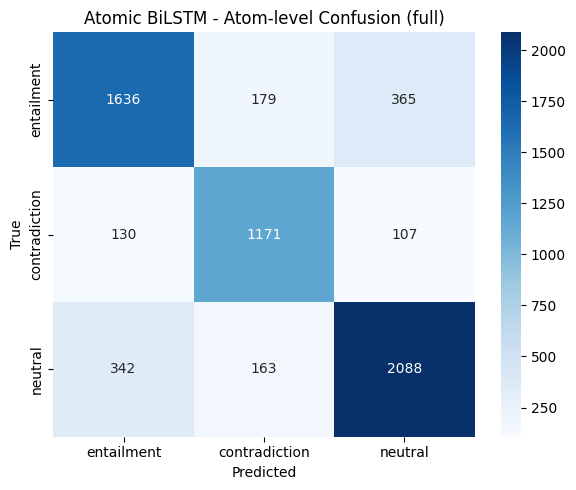

Saved figure -> outputs\test_full\figures\Atomic_BiLSTM_-_Atom-level_Confusion_full.png

Atomic PubMedBERT - ATOM level (6,181 labelled atoms; normal: answer label, mixed: human label)
           n  Accuracy  Macro-F1     MCC  F1_entailment  F1_contradiction  F1_neutral  majority_baseline_acc
half                                                                                                        
all     6181    0.8782    0.8835  0.8146         0.8422            0.9311      0.8773                 0.4195
normal  4504    0.9456    0.9454  0.9178         0.9357            0.9514      0.9491                 0.3930
mixed   1677    0.6971    0.6776  0.4722         0.6286            0.6599      0.7443                 0.4908


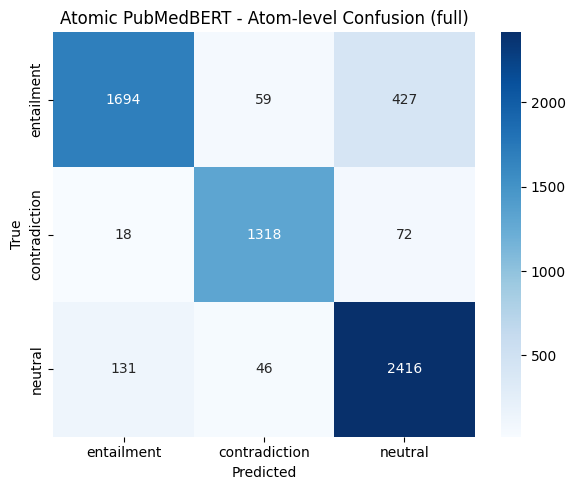

Saved figure -> outputs\test_full\figures\Atomic_PubMedBERT_-_Atom-level_Confusion_full.png


In [24]:
for name, df in atom_preds.items():
    labelled = df[df["has_label"]].assign(true_label=lambda d: d["true_label"].astype(int))
    report_by_half(labelled, f"{name} - ATOM level ({len(labelled):,} labelled atoms; normal: answer label, "
                             f"mixed: human label)")
    plot_confusion(labelled["true_label"].astype(int).tolist(), labelled["pred_label"].tolist(), ID2LABEL,
                   f"{name} - Atom-level Confusion ({MODE})", out_dir=FIG_DIR)

## 5 · Answer-level comparison

- Summary table: model × scope (*covered* / *all*) × half, with the majority baseline
- 2×2 Macro-F1 grid per half, per-class F1, confusion matrices
- McNemar's test between every pair of models (same covered answers), per half
- Accuracy by number of atoms per answer; answers every model gets wrong (`reports/all_models_wrong.csv`)

In [25]:
class ResultsComparator:
    """Compares the models at ANSWER level (one row per answer).
    scope "covered": answers that gave atoms, for every model (like for like; the comparison to report).
    scope "all":     every answer; for the atomic models an answer without atoms follows UNCOVERED_PRED."""
    def __init__(self, answer_preds, classes=CLASSES):
        self.classes   = classes
        self.preds_all = {name: df.copy() for name, df in answer_preds.items()}
        self.mcnemar_p = {}
        if self.preds_all:
            shared = set.intersection(*(set(df.loc[df["covered"], "source_row"]) for df in self.preds_all.values()))
            for df in self.preds_all.values():
                df["covered"] = df["source_row"].isin(shared)
            print(f"Answers covered for every model: {len(shared):,} of {len(answers):,}")

    def summary_table(self):
        tables = []
        for name, df in self.preds_all.items():
            for scope, part in (("covered", df[df["covered"]]), ("all", df)):
                t = scores_by_half(part).reset_index()
                t.insert(0, "scope", scope)
                t.insert(0, "Model", name)
                tables.append(t)
        self.summary = pd.concat(tables).set_index(["Model", "scope", "half"]).round(4)
        print("=" * 100)
        print(f"RESULTS ({MODE}, answer level). covered = answers with >= 1 atom; all = every answer "
              f"(atomic models, answers without atoms: {UNCOVERED_PRED or 'counted wrong'})")
        print("=" * 100)
        print(self.summary.to_string())
        return self

    def _metric(self, model, scope, half, col="Macro-F1"):
        try:
            return self.summary.loc[(model, scope, half), col]
        except KeyError:
            return float("nan")

    def plot_grid(self):
        fig, axes = plt.subplots(1, len(HALVES), figsize=(5.5 * len(HALVES), 3.2), squeeze=False)
        for ax, half in zip(axes[0], HALVES):
            grid = pd.DataFrame({
                "BiLSTM":     [self._metric("Holistic BiLSTM", "covered", half),
                               self._metric("Atomic BiLSTM", "covered", half)],
                "PubMedBERT": [self._metric("Holistic PubMedBERT", "covered", half),
                               self._metric("Atomic PubMedBERT", "covered", half)],
            }, index=["Holistic", "Atomic"])
            sns.heatmap(grid, annot=True, fmt=".4f", cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5, ax=ax, cbar=False)
            ax.set_title(f"Macro-F1, {half} half (covered)" + (" - C/N only" if half == "mixed" else ""),
                         fontsize=11, fontweight="bold")
            ax.set_xlabel("Model Architecture"); ax.set_ylabel("Granularity")
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "results_2x2_grid.png"), dpi=150); plt.show()
        return self

    def plot_perclass_bars(self):
        names = list(self.preds_all)
        fig, axes = plt.subplots(1, len(HALVES), figsize=(7 * len(HALVES), 4.5), squeeze=False)
        for ax, half in zip(axes[0], HALVES):
            classes = [c for c in self.classes
                       if any(pd.notna(self._metric(n, "covered", half, f"F1_{c}")) for n in names)]
            x, w = np.arange(len(classes)), 0.8 / max(len(names), 1)
            for i, name in enumerate(names):
                ax.bar(x + i * w, [self._metric(name, "covered", half, f"F1_{c}") for c in classes], w,
                       label=name, alpha=0.85)
            ax.set_xticks(x + w * (len(names) - 1) / 2); ax.set_xticklabels(classes, fontsize=11)
            ax.set_ylim(0, 1.05); ax.set_ylabel("F1 Score"); ax.grid(axis="y", alpha=0.3)
            ax.set_title(f"Per-class F1, {half} half (covered)", fontsize=12); ax.legend(fontsize=8)
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "results_perclass_f1.png"), dpi=150); plt.show()
        return self

    def plot_confusions(self):
        fig, axes = plt.subplots(2, 2, figsize=(14, 11))
        for ax in axes.flat[len(self.preds_all):]:
            ax.axis("off")
        for ax, name in zip(axes.flat, self.preds_all):
            df = self.preds_all[name]
            df = df[df["covered"]]
            cm = confusion_matrix(df["true_label"], df["pred_label"], labels=list(range(len(self.classes))))
            sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                        xticklabels=self.classes, yticklabels=self.classes, ax=ax, cbar=False)
            ax.set_title(name, fontsize=11, fontweight="bold"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        plt.suptitle(f"Confusion Matrices ({MODE}, covered answers)", fontsize=14, fontweight="bold", y=1.01)
        plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "results_confusion_matrices.png"), dpi=150); plt.show()
        return self

    @staticmethod
    def _mcnemar_test(y_true, y_pred1, y_pred2):
        """Continuity-corrected McNemar's test. b/c = model1/2 uniquely correct."""
        b = sum(1 for yt, yp1, yp2 in zip(y_true, y_pred1, y_pred2) if yp1 == yt and yp2 != yt)
        c = sum(1 for yt, yp1, yp2 in zip(y_true, y_pred1, y_pred2) if yp1 != yt and yp2 == yt)
        if (b + c) == 0:
            return float("nan"), float("nan")
        stat = (abs(b - c) - 1) ** 2 / (b + c)
        p    = 1 - chi2.cdf(stat, df=1)
        return round(stat, 3), round(p, 4)

    def mcnemar_pairs(self):
        names = list(self.preds_all)
        print(f"McNemar on covered answers\n{'Pair':54s}  {'half':>6}  {'chi2':>8}  {'p-value':>8}  Sig?")
        print("-" * 90)
        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                n1, n2 = names[i], names[j]
                d1 = self.preds_all[n1].query("covered").set_index("source_row")
                d2 = self.preds_all[n2].query("covered").set_index("source_row")
                for half in halves_of(d1):
                    rows = d1.index if half == "all" else d1.index[d1["gen_mode"] == half]
                    rows = rows.intersection(d2.index)
                    if len(rows) < 20:
                        print(f"  {n1:25s} vs {n2:25s}  {half:>6}  too few answers ({len(rows)})")
                        continue
                    stat, p = self._mcnemar_test(d1.loc[rows, "true_label"].tolist(),
                                                 d1.loc[rows, "pred_label"].tolist(),
                                                 d2.loc[rows, "pred_label"].tolist())
                    self.mcnemar_p[(frozenset((n1, n2)), half)] = p
                    sig = "yes" if isinstance(p, float) and p < 0.05 else ""
                    print(f"  {n1:25s} vs {n2:25s}  {half:>6}  {stat:>8}  {p:>8}  {sig}")
        return self

    def aggregation_quality(self):
        for name, df in self.preds_all.items():
            if "n_triplets" not in df.columns:
                continue
            df = df[df["covered"]].copy()
            df["atoms"] = pd.cut(df["n_triplets"], bins=[0, 1, 3, 6, 100], labels=["1", "2-3", "4-6", "7+"])
            print(f"\n{name} - accuracy by number of atoms per answer (covered):")
            print(df.groupby(["gen_mode", "atoms"], observed=True)["correct"].agg(["mean", "count"]).round(3).to_string())
        return self

    def error_analysis(self, show=5):
        wrong = None
        for df in self.preds_all.values():
            w = set(df.loc[df["covered"] & ~df["correct"].astype(bool), "source_row"])
            wrong = w if wrong is None else wrong & w
        wrong = sorted(wrong or [])
        print(f"\nCovered answers every model gets wrong: {len(wrong)}")
        for _, row in answers[answers["source_row"].isin(wrong[:show])].iterrows():
            print(f"  [{row['gen_mode']}, {row['label']}] {str(row['premise'])[:90]}...\n      -> {str(row['hypothesis'])[:110]}...")
        pd.DataFrame({"source_row": wrong}).merge(answers, on="source_row").to_csv(
            os.path.join(REPORT_DIR, "all_models_wrong.csv"), index=False)
        return self

    def export(self):
        path = os.path.join(REPORT_DIR, "results_summary.csv")
        self.summary.to_csv(path)
        print(f"\nSaved -> {path}")
        return self

    def run_all(self):
        return (self.summary_table().plot_grid().plot_perclass_bars().plot_confusions()
                    .mcnemar_pairs().aggregation_quality().error_analysis().export())

Answers covered for every model: 2,161 of 2,298
RESULTS (full, answer level). covered = answers with >= 1 atom; all = every answer (atomic models, answers without atoms: counted wrong)
                                       n  Accuracy  Macro-F1     MCC  F1_entailment  F1_contradiction  F1_neutral  majority_baseline_acc
Model               scope   half                                                                                                        
Holistic BiLSTM     covered all     2161    0.8112    0.8068  0.7216         0.7458            0.8298      0.8449                 0.4299
                            normal  1762    0.9228    0.9209  0.8845         0.8804            0.8971      0.9854                 0.3513
                            mixed    399    0.3183    0.3447 -0.0481            NaN            0.2105      0.4788                 0.7769
                    all     all     2298    0.8142    0.8119  0.7264         0.7616            0.8280      0.8461                 

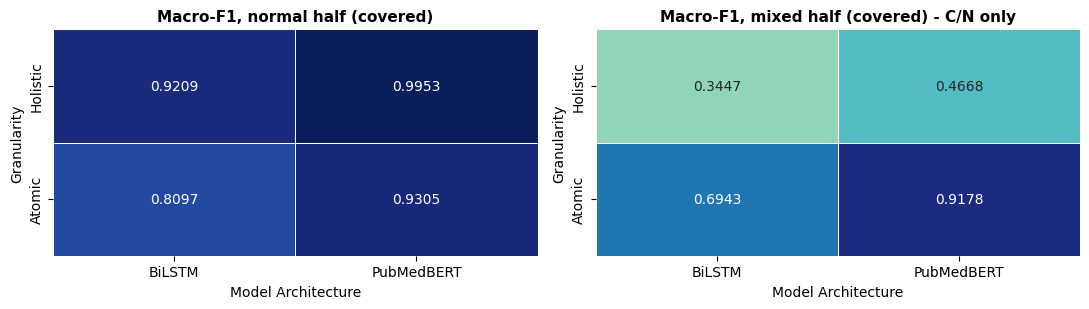

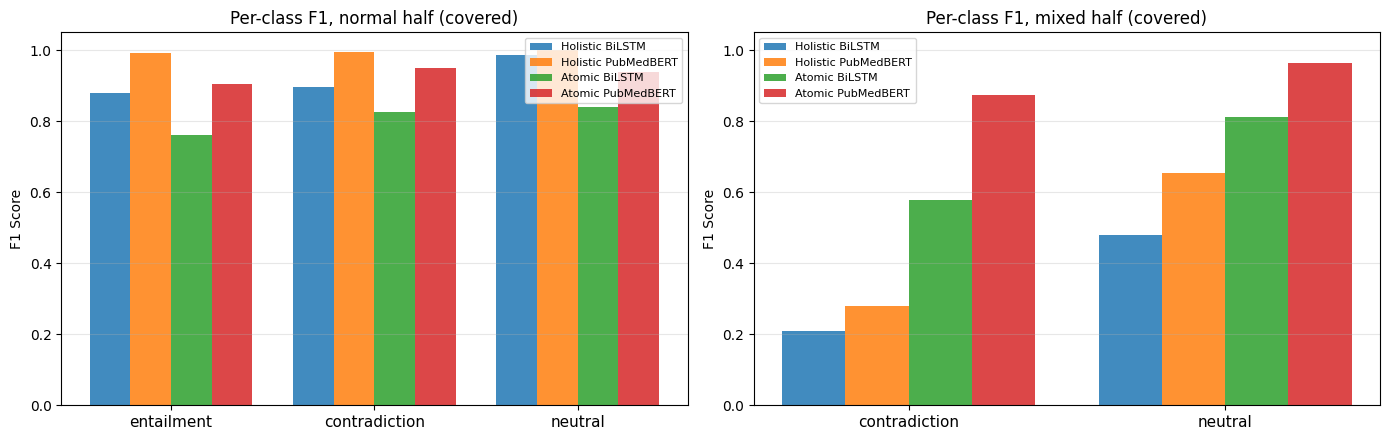

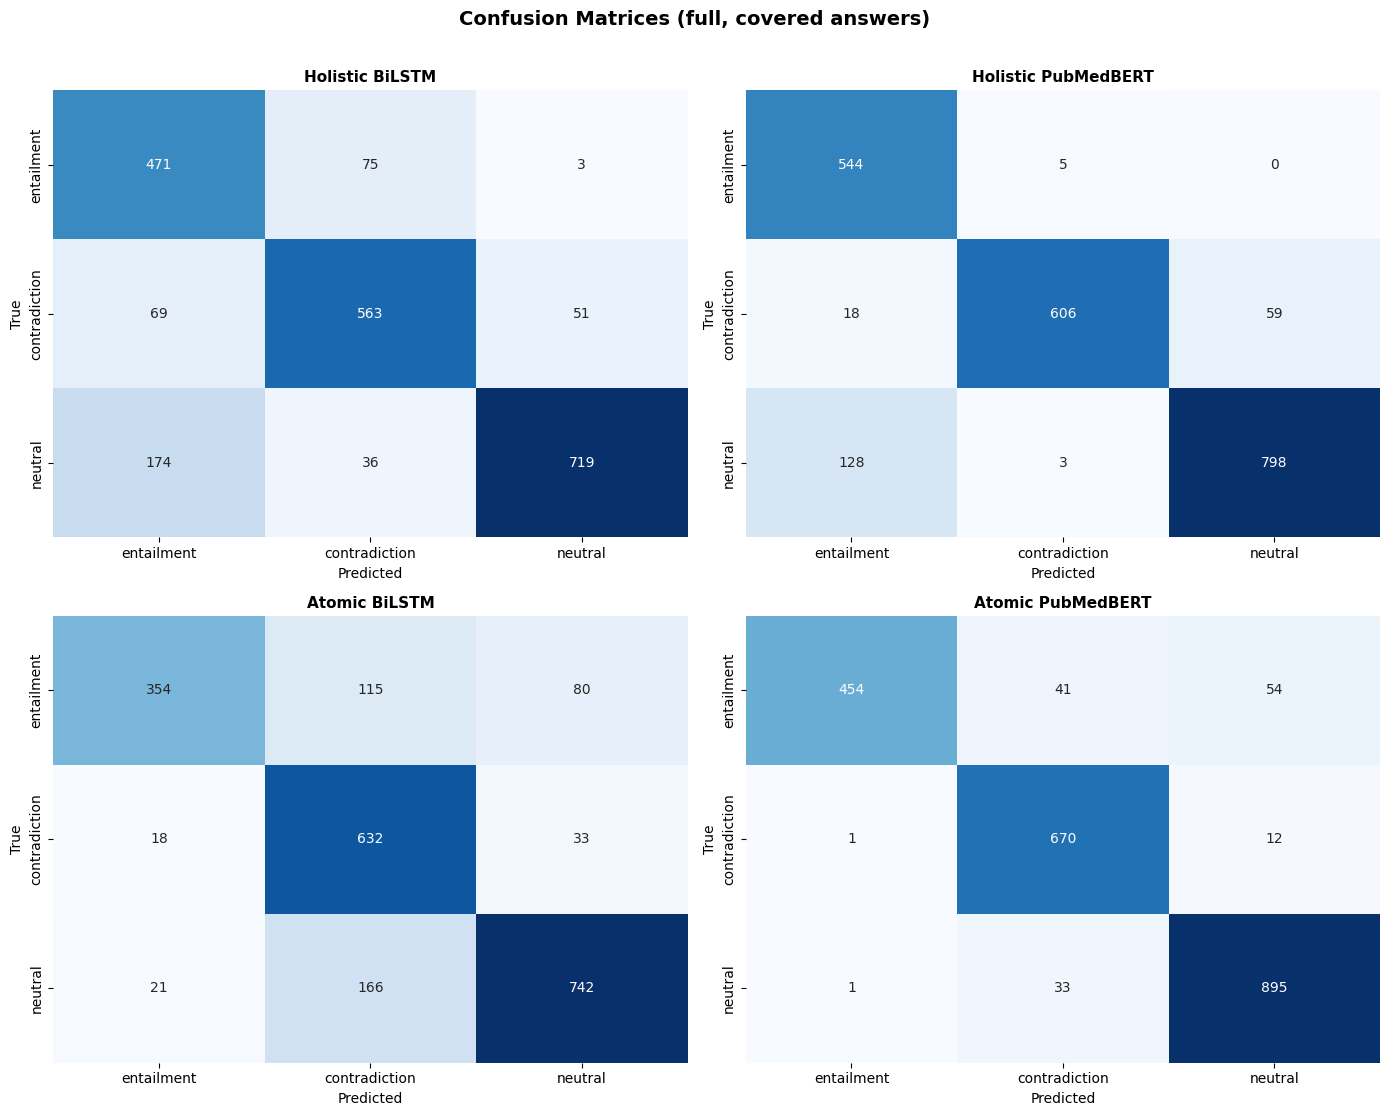

McNemar on covered answers
Pair                                                      half      chi2   p-value  Sig?
------------------------------------------------------------------------------------------
  Holistic BiLSTM           vs Holistic PubMedBERT           all   167.271       0.0  yes
  Holistic BiLSTM           vs Holistic PubMedBERT        normal   118.596       0.0  yes
  Holistic BiLSTM           vs Holistic PubMedBERT         mixed    48.944       0.0  yes
  Holistic BiLSTM           vs Atomic BiLSTM                 all     1.034    0.3092  
  Holistic BiLSTM           vs Atomic BiLSTM              normal   105.865       0.0  yes
  Holistic BiLSTM           vs Atomic BiLSTM               mixed   126.042       0.0  yes
  Holistic BiLSTM           vs Atomic PubMedBERT             all   154.002       0.0  yes
  Holistic BiLSTM           vs Atomic PubMedBERT          normal      1.34     0.247  
  Holistic BiLSTM           vs Atomic PubMedBERT           mixed   232.091     

In [26]:
comparator = ResultsComparator(answer_preds).run_all()

## 6 · FActScore

Share of an answer's atoms the model calls entailment, averaged per answer label.


=== FActScore -- Atomic BiLSTM ===
FActScore(M) = 0.3290   (mean over 2,161 answers with atoms)
                          mean  count
gen_mode answer_label                
mixed    contradiction  0.1876     89
         neutral        0.4441    310
normal   contradiction  0.0940    594
         entailment     0.8050    549
         neutral        0.0952    619

=== FActScore -- Atomic PubMedBERT ===
FActScore(M) = 0.2934   (mean over 2,161 answers with atoms)
                          mean  count
gen_mode answer_label                
mixed    contradiction  0.1455     89
         neutral        0.3136    310
normal   contradiction  0.0109    594
         entailment     0.9117    549
         neutral        0.0272    619


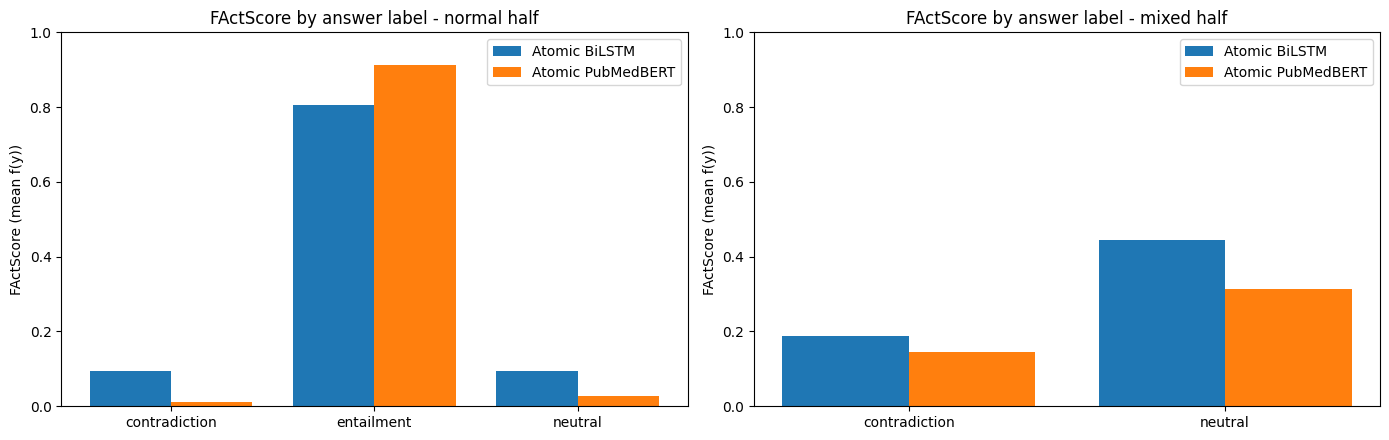

            model  factscore  n_answers  factscore_mixed_contradiction  factscore_mixed_neutral  factscore_normal_contradiction  factscore_normal_entailment  factscore_normal_neutral
    Atomic BiLSTM     0.3290       2161                         0.1876                   0.4441                          0.0940                       0.8050                    0.0952
Atomic PubMedBERT     0.2934       2161                         0.1455                   0.3136                          0.0109                       0.9117                    0.0272


In [27]:
class FActScoreEvaluator:
    """FActScore f(y) per answer = share of its atoms the model predicts as entailment (all atoms, labelled or
    not). Answers are keyed by `source_row`; each keeps its half and its answer label."""
    def __init__(self, id2label):
        self.entail_id = next(k for k, v in id2label.items() if v == "entailment")

    def score(self, atom_df):
        rows = []
        for src_row, g in atom_df.groupby("source_row"):
            rows.append({"source_row": src_row, "original_id": g["original_id"].iloc[0],
                         "gen_mode": g["gen_mode"].iloc[0], "answer_label": str(g["response_label"].iloc[0]),
                         "n_triplets": len(g), "f_y": (g["pred_label"] == self.entail_id).mean()})
        return pd.DataFrame(rows)

    def report(self, atom_df, model_name):
        per_answer = self.score(atom_df)
        print(f"\n=== FActScore -- {model_name} ===")
        print(f"FActScore(M) = {per_answer['f_y'].mean():.4f}   (mean over {len(per_answer):,} answers with atoms)")
        print(per_answer.groupby(["gen_mode", "answer_label"])["f_y"].agg(["mean", "count"]).round(4).to_string())
        return per_answer


def plot_factscore_comparison(factscore_results):
    fig, axes = plt.subplots(1, len(HALVES), figsize=(7 * len(HALVES), 4.5), squeeze=False)
    for ax, half in zip(axes[0], HALVES):
        labels = sorted(set(l for df in factscore_results.values()
                            for l in df.loc[df["gen_mode"] == half, "answer_label"].unique()))
        x, width = np.arange(len(labels)), 0.8 / max(len(factscore_results), 1)
        for i, (name, df) in enumerate(factscore_results.items()):
            part = df[df["gen_mode"] == half]
            ax.bar(x + i * width, [part.loc[part["answer_label"] == l, "f_y"].mean() for l in labels], width, label=name)
        ax.set_xticks(x + width * (len(factscore_results) - 1) / 2); ax.set_xticklabels(labels)
        ax.set_ylabel("FActScore (mean f(y))"); ax.set_ylim(0, 1)
        ax.set_title(f"FActScore by answer label - {half} half"); ax.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "factscore_by_answer_label.png"), dpi=150)
    plt.show()


factscore_results, factscore_rows = {}, []
for name, df in atom_preds.items():
    per_answer = FActScoreEvaluator(ID2LABEL).report(df, name)
    factscore_results[name] = per_answer
    factscore_rows.append({"model": name, "factscore": per_answer["f_y"].mean(), "n_answers": len(per_answer),
                           **{f"factscore_{h}_{l}": g["f_y"].mean()
                              for (h, l), g in per_answer.groupby(["gen_mode", "answer_label"])}})
if factscore_results:
    plot_factscore_comparison(factscore_results)
    factscore_summary = pd.DataFrame(factscore_rows)
    factscore_summary.to_csv(os.path.join(REPORT_DIR, "factscore_summary.csv"), index=False)
    print(factscore_summary.round(4).to_string(index=False))
else:
    print("No atomic model loaded.")

## 7 · Summary

Best model per half, the two factors of the 2×2 design (granularity and architecture) with McNemar p-values, and every model's val score (4a) next to its test scores.

In [28]:
S = comparator.summary.reset_index()
halves = list(dict.fromkeys(S["half"]))                    # all (full mode only), normal, mixed
nan = float("nan")
metric = comparator._metric

# 1. Best model per half (covered answers, by Macro-F1)
best_rows = []
for half in halves:
    g = S[(S["scope"] == "covered") & (S["half"] == half)].sort_values("Macro-F1", ascending=False)
    top, second = g.iloc[0], (g.iloc[1] if len(g) > 1 else None)
    best_rows.append({"half": half, "best model": top["Model"], "Macro-F1": top["Macro-F1"],
                      "Accuracy": top["Accuracy"], "MCC": top["MCC"],
                      "runner-up": second["Model"] if second is not None else "",
                      "lead (Macro-F1)": top["Macro-F1"] - second["Macro-F1"] if second is not None else nan,
                      "McNemar p vs runner-up": comparator.mcnemar_p.get(
                          (frozenset((top["Model"], second["Model"])), half), nan) if second is not None else nan,
                      "majority baseline acc": top["majority_baseline_acc"]})
best = pd.DataFrame(best_rows).set_index("half")

# 2. The two factors of the 2x2 design (Macro-F1 difference on covered answers, McNemar p on the same answers)
effect_rows = []
for half in halves:
    for a, b, label in [("Holistic BiLSTM", "Atomic BiLSTM", "atomic - holistic (BiLSTM)"),
                        ("Holistic PubMedBERT", "Atomic PubMedBERT", "atomic - holistic (PubMedBERT)"),
                        ("Holistic BiLSTM", "Holistic PubMedBERT", "PubMedBERT - BiLSTM (holistic)"),
                        ("Atomic BiLSTM", "Atomic PubMedBERT", "PubMedBERT - BiLSTM (atomic)")]:
        effect_rows.append({"half": half, "comparison": label,
                            "Macro-F1 diff": metric(b, "covered", half) - metric(a, "covered", half),
                            "McNemar p": comparator.mcnemar_p.get((frozenset((a, b)), half), nan)})
effects = pd.DataFrame(effect_rows).set_index(["half", "comparison"])

# 3. Every model: val (from 4a) next to test, covered and end-to-end
fs = {r["model"]: r["factscore"] for r in factscore_rows}
models = pd.DataFrame({name: {"val Macro-F1 (4a)": model_info[name]["val_macro_f1"],
                              **{f"test Macro-F1 {h}, covered": metric(name, "covered", h) for h in halves},
                              **{f"test Macro-F1 {h}, end-to-end": metric(name, "all", h) for h in halves},
                              "FActScore": fs.get(name, nan)}
                       for name in comparator.preds_all}).T

pd.set_option("display.width", 200)
print(f"SUMMARY - mode {MODE} ({' + '.join(HALVES)}), {len(answers):,} test answers, "
      f"{int(answers['covered'].sum()):,} with atoms\n")
print("Best model per half (covered answers, by Macro-F1):")
print(best.round(4).to_string())
print("\nThe 2x2 factors (Macro-F1 of the first named minus the second; positive = the first named is better):")
print(effects.round(4).to_string())
print("\nAll models:")
print(models.round(4).to_string())
for half, r in best.iterrows():
    below = r["Accuracy"] < r["majority baseline acc"]
    print(f"\n- {half}: best is {r['best model']} (Macro-F1 {r['Macro-F1']:.4f}, accuracy {r['Accuracy']:.1%}; "
          f"always predicting the most common label gives {r['majority baseline acc']:.1%} accuracy"
          + ("; its accuracy is BELOW that baseline)" if below else ")"))

best.to_csv(os.path.join(REPORT_DIR, "summary_best_model.csv"))
effects.to_csv(os.path.join(REPORT_DIR, "summary_2x2_effects.csv"))
models.to_csv(os.path.join(REPORT_DIR, "summary_models.csv"))
print(f"\nSaved -> {REPORT_DIR}/summary_best_model.csv, summary_2x2_effects.csv, summary_models.csv")

SUMMARY - mode full (normal + mixed), 2,298 test answers, 2,161 with atoms

Best model per half (covered answers, by Macro-F1):
                 best model  Macro-F1  Accuracy     MCC            runner-up  lead (Macro-F1)  McNemar p vs runner-up  majority baseline acc
half                                                                                                                                        
all       Atomic PubMedBERT    0.9299    0.9343  0.9004  Holistic PubMedBERT           0.0278                  0.0001                 0.4299
normal  Holistic PubMedBERT    0.9953    0.9955  0.9932    Atomic PubMedBERT           0.0648                  0.0000                 0.3513
mixed     Atomic PubMedBERT    0.9178    0.9424  0.8359        Atomic BiLSTM           0.2235                  0.0000                 0.7769

The 2x2 factors (Macro-F1 of the first named minus the second; positive = the first named is better):
                                       Macro-F1 diff  McNemar p
